# Baselines comparison — exp 01 / 02 / 03 on `can/ph`

Aggregates the headline success rates of the three completed experiments on the same axis, with 95% Wilson confidence intervals. The whole point of the project's hybrid method (exp 05) is to close the gap between BC (exp 03) and replay (exp 01).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('..')
exp01 = json.loads((ROOT / 'experiments/01_demo_replay/results/can_ph.json').read_text())
exp02 = json.loads((ROOT / 'experiments/02_random_baseline/results/can_ph.json').read_text())
exp03 = json.loads((ROOT / 'experiments/03_bc_baseline/results/can_ph.json').read_text())

rows = [
    ('01: demo replay\n(upper bound)', exp01['success_rate'], exp01['n_demos_attempted']),
    ('02: random\n(lower bound)',     exp02['success_rate'], exp02['n_total']),
    ('03: behaviour\ncloning',         exp03['success_rate'], exp03['n_total']),
]

for label, rate, n in rows:
    print(f'{label.replace(chr(10), " ")}: {rate:.3f} (n={n})')

01: demo replay (upper bound): 0.900 (n=20)
02: random (lower bound): 0.000 (n=60)
03: behaviour cloning: 0.067 (n=60)


## Bar chart with Wilson 95% CI

Wilson intervals (rather than normal-approximation) since the exp 02 success rate is at 0 and the normal approximation degenerates at the boundary.

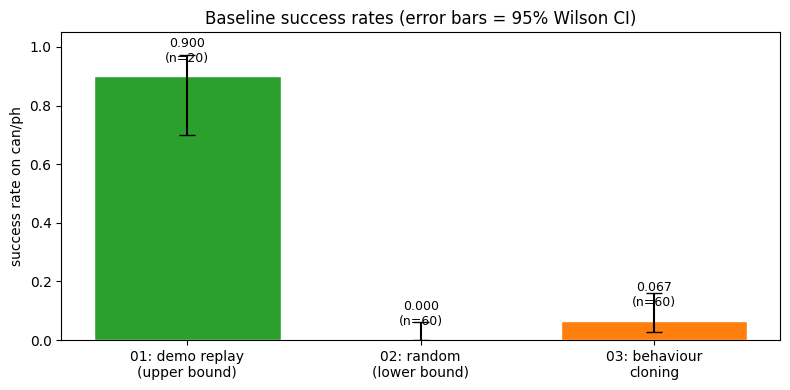

In [2]:
def wilson_ci(p, n, z=1.96):
    """Two-sided Wilson 95% CI for a binomial proportion."""
    if n == 0:
        return 0.0, 0.0
    denom = 1.0 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = (z * np.sqrt(p * (1.0 - p) / n + z**2 / (4 * n**2))) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

labels = [r[0] for r in rows]
rates = np.array([r[1] for r in rows])
ns = np.array([r[2] for r in rows])

lo_hi = np.array([wilson_ci(p, n) for p, n in zip(rates, ns)])
yerr = np.array([rates - lo_hi[:, 0], lo_hi[:, 1] - rates])

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, rates, yerr=yerr, capsize=6,
              color=['tab:green', 'tab:red', 'tab:orange'],
              edgecolor='white')
ax.set_ylim(0, 1.05)
ax.set_ylabel('success rate on can/ph')
ax.set_title('Baseline success rates (error bars = 95% Wilson CI)')
for bar, rate, n in zip(bars, rates, ns):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.05,
            f'{rate:.3f}\n(n={n})', ha='center', fontsize=9)
ax.axhline(0, color='k', linewidth=0.5)
plt.tight_layout()
plt.show()

## Gap to close

Replay sets a non-trivial *upper bound* (90%, not 100%, because of the documented robosuite drift); BC currently sits ~7 percentage points above the random floor. The hybrid method (exp 05) is designed to push the closed-loop number up toward the replay ceiling by adding an online MBD score correction on top of the BC prior.

In [3]:
gap_random_bc = rates[2] - rates[1]
gap_bc_replay = rates[0] - rates[2]
print(f'Gap random → BC : {gap_random_bc:+.3f}')
print(f'Gap BC → replay : {gap_bc_replay:+.3f}  ← target for exp 05')

Gap random → BC : +0.067
Gap BC → replay : +0.833  ← target for exp 05
